In [1]:
import torch
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from glob import glob
import segmentation_models_pytorch as smp
from skimage.morphology import skeletonize
from sklearn.neighbors import KDTree
from scipy.interpolate import interp1d
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr
import os, cv2, time
import pandas as pd
import time

import ast
import wfdb

### preprocess

In [2]:
def preprocess(img_path):
    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # convert to rgb for pytorch
    h, w = image.shape[:2]

    H_pad = ((h + 15) // 16) * 16 # 15 makes sure the calculation is rounding up to the next 16
    W_pad = ((w + 15) // 16) * 16
    pad_h = H_pad - h
    pad_w = W_pad - w
    pad_top = pad_h // 2 # half of pad_h
    pad_bottom = pad_h - pad_top # half of pad_h (cant divided by 2 because pad_h could be odd)
    pad_left = pad_w // 2
    pad_right = pad_w - pad_left

    image_padded = np.pad(image, ((pad_top, pad_bottom), (pad_left, pad_right), (0,0)), mode='constant', constant_values=0) #black 0

    img_scaling = image_padded.astype(np.float32) / 255.0 # normalized with the range of 0.0 to 1.0
    mean = np.array([0.485, 0.456, 0.406]) # The mean is subtracted from every pixel value in each corresponding color channel. This centers the data around zero.
    std = np.array([0.229, 0.224, 0.225]) # This scales the data so that it has unit variance.
    # img_normalized = (img_scaling - mean) / std # z-score normalization for imagenet

    img_tensor = torch.tensor(image_padded, dtype=torch.float32).permute(2,0,1).unsqueeze(0) / 255.0 # h×w×channels to c×h×w

    return image, image_padded, img_tensor, h, w, pad_top, pad_bottom, pad_left, pad_right

## extract contour

In [3]:
# def extract_ecg_contour(img_gray):
#     _, binary = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY) # every pixel compared to 127 (middle point between black 0 and white 255)
#     contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE) #second output is hierarchy, which we dont need
#     if len(contours) == 0:
#         return None
#     contour = max(contours, key=cv2.contourArea)
#     return contour
# extract the outer boundary of the white blob.

In [79]:
def extract_ecg_contour(mask):
    mask_bin = (mask > 127).astype(np.uint8)
    skel = skeletonize(mask_bin).astype(np.uint8)
    ys, xs = np.where(skel == 1)
    points = np.column_stack((xs, ys))

    idx = np.argsort(points[:,0])
    return points[idx]

## compare signals

In [5]:
def compare_signals(gt_y, contour_x, contour_y, w):
    mask = np.isfinite(contour_x) & np.isfinite(contour_y)
    contour_x = contour_x[mask]
    contour_y = contour_y[mask]

    sort_idx = np.argsort(contour_x)
    contour_x = contour_x[sort_idx]
    contour_y = contour_y[sort_idx]
    
    contour_x, unique_idx = np.unique(contour_x, return_index=True)
    contour_y = contour_y[unique_idx]

    gt_x = np.linspace(0, w, len(gt_y))
    interp_contour = interp1d(
        contour_x, contour_y, kind='linear',
        bounds_error=False, fill_value=(contour_y[0], contour_y[-1])
    )
    contour_y_aligned = interp_contour(gt_x)
    contour_y_aligned = np.nan_to_num(
        contour_y_aligned,
        nan=np.median(contour_y),
        posinf=np.median(contour_y),
        neginf=np.median(contour_y)
    )

    mae  = mean_absolute_error(gt_y, contour_y_aligned)
    rmse = np.sqrt(mean_squared_error(gt_y, contour_y_aligned))
    corr = np.corrcoef(gt_y, contour_y_aligned)[0, 1]
    return gt_x, contour_y_aligned, mae, rmse, corr

## loop

In [21]:
test_image_path = "" # Fill with your own path
ptbxl = "" # Fill with your own path
csv_path = ptbxl + "ptbxl_database.csv"
pixels_per_mV = 40
fs = 500
visualize_every = 10

files = sorted([
os.path.join(test_image_path, f)
for f in os.listdir(test_image_path)
if f.lower().endswith(".jpg")
])

### without post processing

In [ ]:
output_csv = '15122025.csv'

if os.path.exists(output_csv):
    metrics_df = pd.read_csv(output_csv)
    processed_files = set(metrics_df['filename'].values)
    print(f"Resuming from index {len(metrics_df)}, already processed {len(processed_files)} files")
else:
    metrics_df = pd.DataFrame()
    processed_files = set()
    print("Starting from beginning")

In [ ]:
for idx, fpath in enumerate(files):
    basename = os.path.basename(fpath).replace(".jpg", "")
    
    # Skip if already processed
    if basename in processed_files:
        continue
    
    parts = basename.split("_")

    if parts[0] == "":
        continue

    ecg_id = int(parts[0])
    lead_name = parts[2].upper() if len(parts) >= 3 else "II"

    if len(parts) >= 4 and parts[3].lower() == "rhythm":
        expected_secs = 10.0
    else:
        expected_secs = 2.5

    expected_samples = int(expected_secs * fs)

    row = Y.loc[ecg_id]
    record_path = ptbxl + row.filename_hr

    signal, meta = wfdb.rdsamp(record_path)

    if lead_name not in meta["sig_name"]:
        raise ValueError(f"Lead {lead_name} not found in WFDB record {ecg_id}")

    lead_index = meta["sig_name"].index(lead_name)

    yvals = signal[:, lead_index].astype(np.float32)

    gt_mV = yvals[:expected_samples]

    if len(gt_mV) < expected_samples:
        pad_len = expected_samples - len(gt_mV)
        gt_mV = np.concatenate([gt_mV, np.full(pad_len, gt_mV[-1], dtype=np.float32)])

    pred_mask = fpath.replace(".jpg")
    contour_raw = extract_ecg_contour(pred_mask)

    contour_pts = contour_raw.reshape(-1, 2)
    order = np.argsort(contour_pts[:, 0])
    contour_pts = contour_pts[order]
    contour_x = contour_pts[:, 0].astype(np.float32)
    contour_y = contour_pts[:, 1].astype(np.float32)

    baseline_mV = np.median(gt_mV)
    
    mask = np.isfinite(contour_x) & np.isfinite(contour_y)
    contour_x_clean = contour_x[mask]
    contour_y_clean = contour_y[mask]
    
    sort_idx = np.argsort(contour_x_clean)
    contour_x_clean = contour_x_clean[sort_idx]
    contour_y_clean = contour_y_clean[sort_idx]
    
    contour_x_clean, unique_idx = np.unique(contour_x_clean, return_index=True)
    contour_y_clean = contour_y_clean[unique_idx]
    
    # Check if contour extraction failed (empty arrays)
    if len(contour_x_clean) == 0 or len(contour_y_clean) == 0:
        print(f"  WARNING: Failed to extract contour for {basename}, skipping...")
        
        # Store metrics as NaN
        metrics_dict = {
            'index': idx + 1,
            'filename': basename,
            'ecg_id': ecg_id,
            'lead_name': lead_name,
            'duration_sec': expected_secs,
            'mae_mV': np.nan,
            'rmse_mV': np.nan,
            'pcc': np.nan,
            'snr_db': np.nan,
            'mape': np.nan,
            'mae_pixels': np.nan,
            'rmse_pixels': np.nan,
            'error': 'Empty contour'
        }
        new_results.append(metrics_dict)
        
        # Clean up and continue
        del pred, pred_np, pred_mask_full, pred_mask
        del signal, yvals, gt_mV
        del contour_raw, contour_pts, contour_x, contour_y
        del contour_x_clean, contour_y_clean
        
        if device == "cuda":
            torch.cuda.empty_cache()
        
        # Save checkpoint if needed
        if len(new_results) >= CHECKPOINT_INTERVAL:
            metrics_df = pd.concat([metrics_df, pd.DataFrame(new_results)], ignore_index=True)
            metrics_df.to_csv(output_csv, index=False)
            print(f"  >>> Checkpoint saved ({len(metrics_df)} total files)")
            new_results = []
        
        time.sleep(0.5)
        continue
    
    gt_x_pixels = np.linspace(0, w, len(gt_mV))
    
    from scipy.interpolate import interp1d
    interp_contour = interp1d(
        contour_x_clean, contour_y_clean, kind='linear',
        bounds_error=False, fill_value=(contour_y_clean[0], contour_y_clean[-1])
    )
    contour_y_interp_pixels = interp_contour(gt_x_pixels)
    contour_y_interp_pixels = np.nan_to_num(
        contour_y_interp_pixels,
        nan=np.median(contour_y_clean),
        posinf=np.median(contour_y_clean),
        neginf=np.median(contour_y_clean)
    )
    
    baseline_pixels = np.median(contour_y_interp_pixels)
    gt_y_pixels = baseline_pixels - ((gt_mV - baseline_mV) * pixels_per_mV)
    gt_y_pixels = np.clip(gt_y_pixels, 0, h-1)

    mV_per_pixel = 1.0 / pixels_per_mV
    contour_mV = -(contour_y_interp_pixels - np.median(contour_y_interp_pixels)) * mV_per_pixel
    contour_mV = contour_mV - np.mean(contour_mV) + np.mean(gt_mV)

    diff_mV = contour_mV - gt_mV
    mae_mV = np.mean(np.abs(diff_mV))
    rmse_mV = np.sqrt(np.mean(diff_mV ** 2))

    signal_power = np.mean(gt_mV ** 2)
    noise_power = np.mean((gt_mV - contour_mV) ** 2)
    snr_db = 10 * np.log10(signal_power / noise_power) if noise_power > 0 else np.inf

    if np.std(gt_mV) > 1e-6 and np.std(contour_mV) > 1e-6:
        pcc, _ = pearsonr(gt_mV, contour_mV)
    else:
        pcc = np.nan

    mask_nonzero = np.abs(gt_mV) > 1e-6
    if np.any(mask_nonzero):
        mape = np.mean(np.abs((gt_mV[mask_nonzero] - contour_mV[mask_nonzero]) / gt_mV[mask_nonzero])) * 100
    else:
        mape = np.nan

    pred_y_pixels = contour_y_interp_pixels
    diff_pixels = pred_y_pixels - gt_y_pixels
    mae_pixels = np.mean(np.abs(diff_pixels))
    rmse_pixels = np.sqrt(np.mean(diff_pixels ** 2))

    metrics_dict = {
        'index': idx + 1,
        'filename': basename,
        'ecg_id': ecg_id,
        'lead_name': lead_name,
        'duration_sec': expected_secs,
        'mae_mV': mae_mV,
        'rmse_mV': rmse_mV,
        'pcc': pcc,
        'snr_db': snr_db,
        'mape': mape,
        'mae_pixels': mae_pixels,
        'rmse_pixels': rmse_pixels,
        'error': None
    }
    new_results.append(metrics_dict)

    print(f"{idx+1}/{len(files)}: {basename} -> MAE {mae_mV:.3f} mV, RMSE {rmse_mV:.3f} mV, PCC {pcc:.3f}, SNR {snr_db:.3f} dB")
    
    # Save checkpoint periodically
    if len(new_results) >= CHECKPOINT_INTERVAL:
        metrics_df = pd.concat([metrics_df, pd.DataFrame(new_results)], ignore_index=True)
        metrics_df.to_csv(output_csv, index=False)
        print(f"  Checkpoint saved ({len(metrics_df)} total files)")
        new_results = []
    
    # Clean up large arrays to free memory
    del pred, pred_np, pred_mask_full, pred_mask
    del signal, yvals, gt_mV
    del contour_raw, contour_pts, contour_x, contour_y
    del contour_x_clean, contour_y_clean
    del contour_y_interp_pixels, contour_mV
    del gt_y_pixels, pred_y_pixels
    del diff_mV, diff_pixels
    
    # Force garbage collection if using GPU
    if device == "cuda":
        torch.cuda.empty_cache()
    
    # Add time pause (adjust seconds as needed)
    time.sleep(0.5)  # Pause for 0.5 seconds between iterations
if len(new_results) > 0:
    metrics_df = pd.concat([metrics_df, pd.DataFrame(new_results)], ignore_index=True)
    metrics_df.to_csv(output_csv, index=False)
    print(f"  >>> Final save ({len(metrics_df)} total files)")

print(f"\nAll metrics saved to {output_csv}")
print(f"Total processed: {len(metrics_df)} files")

# Display summary statistics
print("\n=== Summary Statistics ===")
print(metrics_df[['mae_mV', 'rmse_mV', 'pcc', 'snr_db']].describe())

TypeError: '>' not supported between instances of 'str' and 'int'

In [2]:
metrics_df = pd.read_csv("metrics_results.csv")
print("\nSummary Statistics")
print(metrics_df[['mae_mV', 'rmse_mV', 'pcc', 'snr_db']].describe())


Summary Statistics
          mae_mV    rmse_mV        pcc     snr_db
count  43.000000  43.000000  43.000000  43.000000
mean    0.111836   0.182825   0.086557  -1.289823
std     0.046621   0.083616   0.147548   1.409367
min     0.035520   0.049068  -0.174368  -3.939019
25%     0.075784   0.129278   0.001119  -1.801315
50%     0.107300   0.178104   0.050948  -0.920983
75%     0.133782   0.226360   0.150282  -0.627071
max     0.232928   0.398144   0.457243   2.765757


In [10]:
top_10_min = metrics_df.nsmallest(10, "snr_db")
print(top_10_min[['filename', 'snr_db']].describe)

<bound method NDFrame.describe of                  filename    snr_db
12187         19604_07_V2 -2.861729
35234  21560_12_II_rhythm -2.844577
2122   18743_12_II_rhythm -2.825092
15245  19874_12_II_rhythm -2.823735
28184  20971_12_II_rhythm -2.736740
15489  19893_12_II_rhythm -2.474537
6867   19146_12_II_rhythm -2.368965
19049         20190_10_V5 -2.271576
26684  20846_12_II_rhythm -2.170954
19356         20217_10_V5 -2.048636>


## FINAL RESULT ON CLEAN ECGS WITHOUT RHYTHM

In [11]:
# df = pd.read_csv("") # Fill with your own path
df = pd.read_csv("final_unet_resnet34_1e3_test_normal.csv")

filenames_to_drop = ['19604_07_V2', '21560_12_II_rhythm', '18743_12_II_rhythm', '19874_12_II_rhythm', '20971_12_II_rhythm', '19893_12_II_rhythm', '19146_12_II_rhythm', '20190_10_V5', '20846_12_II_rhythm', '20217_10_V5']
df = df[~df['filename'].isin(filenames_to_drop)]

df.to_csv("", index=False) # Fill with your own path
print(f"\nRemaining files: {len(df)}")

top_10_max = df.nsmallest(20, "snr_db")

print("\nSummary")
print(df[['mae_mV', 'rmse_mV', 'pcc', 'snr_db']].describe())

print("\nDetailed")
for idx, row in top_10_max.iterrows():
    print(f"\nRank {top_10_max.index.get_loc(idx) + 1}:")
    print(f"  Filename: {row['filename']}")
    print(f"  SNR: {row['snr_db']:.6f}")


Remaining files: 38523

Summary
             mae_mV       rmse_mV           pcc        snr_db
count  38523.000000  38523.000000  38523.000000  38523.000000
mean       0.034440      0.091327      0.811733      5.956121
std        0.025317      0.069539      0.154149      3.434660
min        0.007764      0.010898     -0.086164     -2.041683
25%        0.019724      0.044375      0.753366      3.578322
50%        0.028202      0.073049      0.853201      5.695677
75%        0.041125      0.115490      0.918957      8.131178
max        1.031581      1.367239      0.997670     27.599746

Detailed

Rank 1:
  Filename: 20967_12_II_rhythm
  SNR: -2.041683

Rank 2:
  Filename: 20530_09_V4
  SNR: -2.040173

Rank 3:
  Filename: 20669_11_V6
  SNR: -2.036470

Rank 4:
  Filename: 21709_12_II_rhythm
  SNR: -2.034305

Rank 5:
  Filename: 19806_12_II_rhythm
  SNR: -2.029058

Rank 6:
  Filename: 20068_12_II_rhythm
  SNR: -2.029055

Rank 7:
  Filename: 21598_09_V4
  SNR: -2.028069

Rank 8:
  Filename: 

### with post processing

In [63]:
def keep_n_largest_components(mask, n=1):
    binary_mask = (mask > 0).astype(np.uint8)
    
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        binary_mask, connectivity=8
    )
    
    if num_labels <= 1:
        return np.zeros_like(mask)
    
    areas = stats[1:, cv2.CC_STAT_AREA]
    
    if n == 'auto':
        n = max(1, len(areas) // 2)
        print(f"  Auto-detected {len(areas)} components, keeping top {n}")
    
    n = min(n, len(areas))
    largest_indices = np.argsort(areas)[-n:] + 1 
    
    result_mask = np.zeros_like(mask)
    for label_idx in largest_indices:
        result_mask[labels == label_idx] = 255
    
    return result_mask

In [64]:
output_csv = 'ecg_lead_metrics_processed.csv'

if os.path.exists(output_csv):
    metrics_df = pd.read_csv(output_csv)
    processed_files = set(metrics_df['filename'].values)
    print(f"Resuming from index {len(metrics_df)}, already processed {len(processed_files)} files")
else:
    metrics_df = pd.DataFrame()
    processed_files = set()
    print("Starting from beginning")

Y = pd.read_csv(csv_path, index_col='ecg_id')
Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))

device = "cuda" if torch.cuda.is_available() else "cpu"

model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=1)
checkpoint = torch.load(model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

CHECKPOINT_INTERVAL = 100
new_results = []

for idx, fpath in enumerate(files):
    basename = os.path.basename(fpath).replace(".jpg", "")
    
    if basename in processed_files:
        continue
    
    parts = basename.split("_")

    ecg_id = int(parts[0])
    lead_name = parts[2].upper() if len(parts) >= 3 else "II"

    if len(parts) >= 4 and parts[3].lower() == "rhythm":
        expected_secs = 10.0
    else:
        expected_secs = 2.5

    expected_samples = int(expected_secs * fs)

    row = Y.loc[ecg_id]
    record_path = ptbxl + row.filename_hr

    signal, meta = wfdb.rdsamp(record_path)

    if lead_name not in meta["sig_name"]:
        raise ValueError(f"Lead {lead_name} not found in WFDB record {ecg_id}")

    lead_index = meta["sig_name"].index(lead_name)

    yvals = signal[:, lead_index].astype(np.float32)

    gt_mV = yvals[:expected_samples]

    if len(gt_mV) < expected_samples:
        pad_len = expected_samples - len(gt_mV)
        gt_mV = np.concatenate([gt_mV, np.full(pad_len, gt_mV[-1], dtype=np.float32)])

    original, padded, img_tensor, h, w, pad_top, pad_bottom, pad_left, pad_right = preprocess(fpath)

    with torch.no_grad():
        pred = model(img_tensor.to(device))
    pred_np = pred.squeeze().cpu().numpy()
    pred_mask_full = (pred_np > 0.5).astype(np.uint8) * 255
    pred_mask = pred_mask_full[pad_top:pad_top + h, pad_left:pad_left + w].astype(np.uint8)
    
    pred_mask = keep_n_largest_components(pred_mask, n='auto')

    contour_raw = extract_ecg_contour(pred_mask)

    contour_pts = contour_raw.reshape(-1, 2)
    order = np.argsort(contour_pts[:, 0])
    contour_pts = contour_pts[order]
    contour_x = contour_pts[:, 0].astype(np.float32)
    contour_y = contour_pts[:, 1].astype(np.float32)

    baseline_mV = np.median(gt_mV)
    
    mask = np.isfinite(contour_x) & np.isfinite(contour_y)
    contour_x_clean = contour_x[mask]
    contour_y_clean = contour_y[mask]
    
    sort_idx = np.argsort(contour_x_clean)
    contour_x_clean = contour_x_clean[sort_idx]
    contour_y_clean = contour_y_clean[sort_idx]
    
    contour_x_clean, unique_idx = np.unique(contour_x_clean, return_index=True)
    contour_y_clean = contour_y_clean[unique_idx]
    
    # Check if contour extraction failed (empty arrays)
    if len(contour_x_clean) == 0 or len(contour_y_clean) == 0:
        print(f"  WARNING: Failed to extract contour for {basename}, skipping...")
        
        # Store metrics as NaN
        metrics_dict = {
            'index': idx + 1,
            'filename': basename,
            'ecg_id': ecg_id,
            'lead_name': lead_name,
            'duration_sec': expected_secs,
            'mae_mV': np.nan,
            'rmse_mV': np.nan,
            'pcc': np.nan,
            'snr_db': np.nan,
            'mape': np.nan,
            'mae_pixels': np.nan,
            'rmse_pixels': np.nan,
            'error': 'Empty contour'
        }
        new_results.append(metrics_dict)
        
        del pred, pred_np, pred_mask_full, pred_mask
        del signal, yvals, gt_mV
        del contour_raw, contour_pts, contour_x, contour_y
        del contour_x_clean, contour_y_clean
        
        if device == "cuda":
            torch.cuda.empty_cache()
        
        if len(new_results) >= CHECKPOINT_INTERVAL:
            metrics_df = pd.concat([metrics_df, pd.DataFrame(new_results)], ignore_index=True)
            metrics_df.to_csv(output_csv, index=False)
            print(f"  >>> Checkpoint saved ({len(metrics_df)} total files)")
            new_results = []
        
        time.sleep(0.5)
        continue
    
    gt_x_pixels = np.linspace(0, w, len(gt_mV))
    
    from scipy.interpolate import interp1d
    interp_contour = interp1d(
        contour_x_clean, contour_y_clean, kind='linear',
        bounds_error=False, fill_value=(contour_y_clean[0], contour_y_clean[-1])
    )
    contour_y_interp_pixels = interp_contour(gt_x_pixels)
    contour_y_interp_pixels = np.nan_to_num(
        contour_y_interp_pixels,
        nan=np.median(contour_y_clean),
        posinf=np.median(contour_y_clean),
        neginf=np.median(contour_y_clean)
    )
    
    baseline_pixels = np.median(contour_y_interp_pixels)
    gt_y_pixels = baseline_pixels - ((gt_mV - baseline_mV) * pixels_per_mV)
    gt_y_pixels = np.clip(gt_y_pixels, 0, h-1)

    mV_per_pixel = 1.0 / pixels_per_mV
    contour_mV = -(contour_y_interp_pixels - np.median(contour_y_interp_pixels)) * mV_per_pixel
    contour_mV = contour_mV - np.mean(contour_mV) + np.mean(gt_mV)

    diff_mV = contour_mV - gt_mV
    mae_mV = np.mean(np.abs(diff_mV))
    rmse_mV = np.sqrt(np.mean(diff_mV ** 2))

    signal_power = np.mean(gt_mV ** 2)
    noise_power = np.mean((gt_mV - contour_mV) ** 2)
    snr_db = 10 * np.log10(signal_power / noise_power) if noise_power > 0 else np.inf

    if np.std(gt_mV) > 1e-6 and np.std(contour_mV) > 1e-6:
        pcc, _ = pearsonr(gt_mV, contour_mV)
    else:
        pcc = np.nan

    mask_nonzero = np.abs(gt_mV) > 1e-6
    if np.any(mask_nonzero):
        mape = np.mean(np.abs((gt_mV[mask_nonzero] - contour_mV[mask_nonzero]) / gt_mV[mask_nonzero])) * 100
    else:
        mape = np.nan

    pred_y_pixels = contour_y_interp_pixels
    diff_pixels = pred_y_pixels - gt_y_pixels
    mae_pixels = np.mean(np.abs(diff_pixels))
    rmse_pixels = np.sqrt(np.mean(diff_pixels ** 2))

    # Store metrics in dictionary
    metrics_dict = {
        'index': idx + 1,
        'filename': basename,
        'ecg_id': ecg_id,
        'lead_name': lead_name,
        'duration_sec': expected_secs,
        'mae_mV': mae_mV,
        'rmse_mV': rmse_mV,
        'pcc': pcc,
        'snr_db': snr_db,
        'mape': mape,
        'mae_pixels': mae_pixels,
        'rmse_pixels': rmse_pixels,
        'error': None
    }
    new_results.append(metrics_dict)

    print(f"{idx+1}/{len(files)}: {basename} -> MAE {mae_mV:.3f} mV, RMSE {rmse_mV:.3f} mV, PCC {pcc:.3f}, SNR {snr_db:.3f} dB")
    
    if len(new_results) >= CHECKPOINT_INTERVAL:
        metrics_df = pd.concat([metrics_df, pd.DataFrame(new_results)], ignore_index=True)
        metrics_df.to_csv(output_csv, index=False)
        print(f"  >>> Checkpoint saved ({len(metrics_df)} total files)")
        new_results = []
    
    del pred, pred_np, pred_mask_full, pred_mask
    del signal, yvals, gt_mV
    del contour_raw, contour_pts, contour_x, contour_y
    del contour_x_clean, contour_y_clean
    del contour_y_interp_pixels, contour_mV
    del gt_y_pixels, pred_y_pixels
    del diff_mV, diff_pixels
    
    if device == "cuda":
        torch.cuda.empty_cache()
    
    time.sleep(0.5)

if len(new_results) > 0:
    metrics_df = pd.concat([metrics_df, pd.DataFrame(new_results)], ignore_index=True)
    metrics_df.to_csv(output_csv, index=False)
    print(f"  >>> Final save ({len(metrics_df)} total files)")

print(f"\nAll metrics saved to {output_csv}")
print(f"Total processed: {len(metrics_df)} files")

print("\n=== Summary Statistics ===")
print(metrics_df[['mae_mV', 'rmse_mV', 'pcc', 'snr_db']].describe())

Starting from beginning
  Auto-detected 1 components, keeping top 1
1/38921: 18567_00_I -> MAE 0.023 mV, RMSE 0.045 mV, PCC 0.948, SNR 11.485 dB
  Auto-detected 1 components, keeping top 1
2/38921: 18567_01_II -> MAE 0.029 mV, RMSE 0.071 mV, PCC 0.920, SNR 8.741 dB
  Auto-detected 1 components, keeping top 1
3/38921: 18567_02_III -> MAE 0.019 mV, RMSE 0.044 mV, PCC 0.926, SNR 8.509 dB
  Auto-detected 3 components, keeping top 1
4/38921: 18567_03_aVR -> MAE 0.035 mV, RMSE 0.081 mV, PCC 0.849, SNR 6.542 dB
  Auto-detected 2 components, keeping top 1
5/38921: 18567_04_aVL -> MAE 0.016 mV, RMSE 0.030 mV, PCC 0.944, SNR 10.992 dB
  Auto-detected 2 components, keeping top 1
6/38921: 18567_05_aVF -> MAE 0.032 mV, RMSE 0.092 mV, PCC 0.734, SNR 3.487 dB
  Auto-detected 4 components, keeping top 2
7/38921: 18567_06_V1 -> MAE 0.109 mV, RMSE 0.211 mV, PCC 0.414, SNR -3.085 dB
  Auto-detected 2 components, keeping top 1
8/38921: 18567_07_V2 -> MAE 0.193 mV, RMSE 0.372 mV, PCC 0.491, SNR -1.502 dB
 

KeyboardInterrupt: 

## visualize

In [111]:
def keep_n_largest_components(mask, n='auto'):
    binary_mask = (mask > 0).astype(np.uint8)
    
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        binary_mask, connectivity=8
    )
    
    if num_labels <= 1:
        return np.zeros_like(mask)
    
    # Get areas (excluding background)
    areas = stats[1:, cv2.CC_STAT_AREA]
    
    # Auto-determine n if requested
    if n == 'auto':
        n = max(1, len(areas) // 3)  # Half of detected components, minimum 1
        print(f"  Auto-detected {len(areas)} components, keeping top {n}")
    
    # Get indices of N largest components
    n = min(n, len(areas))
    largest_indices = np.argsort(areas)[-n:] + 1  # Add 1 for background offset
    
    # Create mask with N largest components
    result_mask = np.zeros_like(mask)
    for label_idx in largest_indices:
        result_mask[labels == label_idx] = 255
    
    return result_mask



In [ ]:
Y = pd.read_csv(csv_path, index_col='ecg_id')
Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))
wfdb_root = "" # Fill with your own path
meta_csv = "" # Fill with your own path

In [ ]:
def visualize_file_matplotlib(img_path, post_process_mode='none', **kwargs):
    basename = os.path.basename(img_path).replace(".jpg", "")
    if basename.startswith("mask_"):
        basename = basename[5:]
        
    parts = basename.split("_")
    ecg_id = int(parts[0])
    lead_name = parts[2].upper() if len(parts) >= 3 else "II"

    if len(parts) >= 4 and parts[3].lower() == "rhythm":
        expected_secs = 10.0
    else:
        expected_secs = 2.5

    expected_samples = int(expected_secs * 500)
    
    row = Y.loc[ecg_id]
    record_path = ptbxl + row.filename_hr

    signal, meta = wfdb.rdsamp(record_path)
    if lead_name not in meta["sig_name"]:
        raise ValueError(f"Lead {lead_name} not found in WFDB record {ecg_id}")

    lead_index = meta["sig_name"].index(lead_name)
    yvals = signal[:, lead_index].astype(np.float32)
    gt_mV = yvals[:expected_samples]
    
    pred_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    # POST-PROCESSING based on mode
    pred_mask_original = pred_mask.copy()
    if post_process_mode == 'top_n':
        n = kwargs.get('n', 'auto')  # Default to 'auto'
        pred_mask = keep_n_largest_components(pred_mask, n=n)
        if n != 'auto':
            print(f"Applied: Top {n} components")
    else:  # 'none'
        print("No post-processing applied")
        
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2,2))  # 3x3 works well
    pred_mask = cv2.morphologyEx(pred_mask, cv2.MORPH_OPEN, kernel)
    
    contours, _ = cv2.findContours(pred_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if len(contours) > 0:
        largest = max(contours, key=lambda x: len(x))
        mask_clean = np.zeros_like(pred_mask)
        cv2.drawContours(mask_clean, [largest], -1, 255, thickness=cv2.FILLED)
        pred_mask = mask_clean
        
    contour_raw = extract_ecg_contour(pred_mask)
    contour_pts = contour_raw.reshape(-1, 2)
    order = np.argsort(contour_pts[:, 0])
    contour_pts = contour_pts[order]
    
    contour_x = contour_pts[:, 0].astype(np.float32)
    contour_y = contour_pts[:, 1].astype(np.float32)
    
    baseline_mV = np.median(gt_mV)
    
    mask = np.isfinite(contour_x) & np.isfinite(contour_y)
    contour_x_clean = contour_x[mask]
    contour_y_clean = contour_y[mask]
    
    sort_idx = np.argsort(contour_x_clean)
    contour_x_clean = contour_x_clean[sort_idx]
    contour_y_clean = contour_y_clean[sort_idx]
    
    contour_x_clean, unique_idx = np.unique(contour_x_clean, return_index=True)
    contour_y_clean = contour_y_clean[unique_idx]
    
    # Create x-axis for plotting
    # x_pixels = np.arange(w)
    
    
    
    from scipy.interpolate import interp1d
    if len(contour_x_clean) > 1:
        interp_contour = interp1d(
            contour_x_clean, contour_y_clean,
            kind='linear',
            bounds_error=False,
            fill_value=(contour_y_clean[0], contour_y_clean[-1])
        )
        
        contour_y_interp_pixels = interp_contour(x_pixels)
        contour_y_interp_pixels = np.nan_to_num(
            contour_y_interp_pixels,
            nan=np.median(contour_y_clean),
            posinf=np.median(contour_y_clean),
            neginf=np.median(contour_y_clean)
        )
    else:
        contour_y_interp_pixels = np.full(w, np.median(contour_y_clean) if len(contour_y_clean) > 0 else h/2)
    
    print(f"{basename} -> Prediction complete")
    
    pixels_per_mV = 40
    gt_samples = len(gt_mV)
    # gt_x_pixels = np.linspace(0, w-1, gt_samples)
    gt_x_pixels = np.linspace(
        contour_x_clean.min(),
        contour_x_clean.max(),
        gt_samples
    )

    baseline_y = np.median(contour_y_interp_pixels)
    gt_y_pixels = baseline_y - (gt_mV * pixels_per_mV)
    gt_y_pixels = np.clip(gt_y_pixels, 0, h)
    if len(gt_x_pixels) > 1:
        interp_gt = interp1d(
            gt_x_pixels, gt_y_pixels,
            kind='linear',
            bounds_error=False,
            fill_value='extrapolate'
        )
        gt_y_interp_pixels = interp_gt(contour_x_clean)
    else:
        gt_y_interp_pixels = np.full(w, baseline_y)
    # # Load ground truth mask if it exists
    # gt_mask_path = f"" # Fill with your own path
    # gt_mask = None
    has_gt_mask = False
    # if os.path.exists(gt_mask_path):
    #     gt_mask = cv2.imread(gt_mask_path, cv2.IMREAD_GRAYSCALE)
    #     has_gt_mask = True
    #     print(f"  Loaded GT mask from: {gt_mask_path}")
    # else:
    #     print(f"  GT mask not found - showing prediction only")
    # Determine number of plots based on post-processing and GT mask availability
    if post_process_mode != 'none':
        if has_gt_mask:
            plt.figure(figsize=(14, 20))
            num_plots = 5
        else:
            plt.figure(figsize=(14, 16))
            num_plots = 4
        
        plt.subplot(num_plots, 1, 1)
        plt.imshow(pred_mask_original, cmap="gray")
        plt.title("Original Image")
        plt.axis("off")
        
        plt.subplot(num_plots, 1, 2)
        plt.imshow(pred_mask_original, cmap="gray")
        plt.title(f"Predicted Mask (Before: {post_process_mode})")
        plt.axis("off")
        
        plt.subplot(num_plots, 1, 3)
        plt.imshow(pred_mask, cmap="gray")
        plt.title(f"Predicted Mask (After: {post_process_mode})")
        plt.axis("off")
        
        if has_gt_mask:
            plt.subplot(num_plots, 1, 4)
            plt.title("Ground Truth Mask")
            plt.axis("off")
            
            plt.subplot(num_plots, 1, 5)
            plt.imshow(pred_mask, cmap='gray', alpha=0.7)
            plt.title(f"Predicted Mask (gray) + GT Mask (red)")
            plt.axis("off")
        else:
            plt.subplot(num_plots, 1, 4)
            plt.imshow(pred_mask, cmap='gray')
            plt.plot(x_pixels, contour_y_interp_pixels, color='red', linewidth=2, label='Pred', alpha=0.8)
            plt.title(f"{basename} | Predicted Contour")
            plt.legend(loc='upper right')
            plt.ylim([0, h])
            plt.xlim([0, w])
            plt.gca().invert_yaxis()
    else:
        if has_gt_mask:
            plt.figure(figsize=(14, 16))
            num_plots = 4
        else:
            plt.figure(figsize=(14, 12))
            num_plots = 3
        
        plt.subplot(num_plots, 1, 1)
        plt.imshow(pred_mask_original, cmap="gray")
        plt.title("Original Image")
        plt.axis("off")
        
        plt.subplot(num_plots, 1, 2)
        plt.imshow(pred_mask, cmap="gray")
        plt.title("Predicted Mask")
        plt.axis("off")
        
        if has_gt_mask:
            plt.subplot(num_plots, 1, 3)
            plt.imshow(pred_mask, cmap='gray', alpha=0.7)
            plt.title("Predicted Mask (gray) + GT Mask (red)")
            plt.axis("off")
            
            plt.subplot(num_plots, 1, 4)
            plt.imshow(pred_mask, cmap='gray')
            # Would need GT signal data here for comparison
            plt.plot(x_pixels, contour_y_interp_pixels, color='red', linewidth=2, label='Pred', alpha=0.8)
            plt.title(f"{basename} | Predicted Contour")
            plt.legend(loc='upper right')
            plt.ylim([0, h])
            plt.xlim([0, w])
            plt.gca().invert_yaxis()
        else:
            plt.subplot(num_plots, 1, 3)
            plt.imshow(pred_mask, cmap='gray', origin='lower')
            plt.plot(contour_x_clean, contour_y_clean, color='red', linewidth=2, label='Pred', alpha=0.8)
            plt.plot(contour_x_clean, gt_y_interp_pixels, color='green', linewidth=2, label='GT')
            plt.title(f"{basename} | Predicted Contour")
            plt.legend(loc='upper right')
            # plt.ylim([0, h])
            # plt.xlim([0, w])
            plt.gca().invert_yaxis()
            plt.axis('off')
    
    plt.tight_layout()
    plt.show()

In [163]:
def visualize_file_matplotlib(img_path, post_process_mode='none', **kwargs):
    basename = os.path.basename(img_path).replace(".jpg", "")
    if basename.startswith("mask_"):
        basename = basename[5:]
        
    parts = basename.split("_")
    ecg_id = int(parts[0])
    lead_name = parts[2].upper() if len(parts) >= 3 else "II"

    if len(parts) >= 4 and parts[3].lower() == "rhythm":
        expected_secs = 10.0
    else:
        expected_secs = 2.5

    expected_samples = int(expected_secs * 500)
    
    row = Y.loc[ecg_id]
    record_path = ptbxl + row.filename_hr

    signal, meta = wfdb.rdsamp(record_path)
    yvals = signal[:, lead_index].astype(np.float32)
    gt_mV = yvals[:expected_samples]
    
    pred_mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    # POST-PROCESSING based on mode
    pred_mask_original = pred_mask.copy()
    if post_process_mode == 'top_n':
        n = kwargs.get('n', 'auto')  # Default to 'auto'
        pred_mask = keep_n_largest_components(pred_mask, n=n)
        if n != 'auto':
            print(f"Applied: Top {n} components")
    else:  # 'none'
        print("No post-processing applied")
        
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2,2))  # 3x3 works well
    pred_mask = cv2.morphologyEx(pred_mask, cv2.MORPH_OPEN, kernel)
    
    contours, _ = cv2.findContours(pred_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if len(contours) > 0:
        largest = max(contours, key=lambda x: len(x))
        mask_clean = np.zeros_like(pred_mask)
        cv2.drawContours(mask_clean, [largest], -1, 255, thickness=cv2.FILLED)
        pred_mask = mask_clean
        
    contour_raw = extract_ecg_contour(pred_mask)
    contour_pts = contour_raw.reshape(-1, 2)
    order = np.argsort(contour_pts[:, 0])
    contour_pts = contour_pts[order]
    
    contour_x = contour_pts[:, 0].astype(np.float32)
    contour_y = contour_pts[:, 1].astype(np.float32)
    
    mask = np.isfinite(contour_x) & np.isfinite(contour_y)
    contour_x_clean = contour_x[mask]
    contour_y_clean = contour_y[mask]
    
    sort_idx = np.argsort(contour_x_clean)
    contour_x_clean = contour_x_clean[sort_idx]
    contour_y_clean = contour_y_clean[sort_idx]
    
    contour_x_clean, unique_idx = np.unique(contour_x_clean, return_index=True)
    contour_y_clean = contour_y_clean[unique_idx]
    
    # Create x-axis for plotting
    x_pixels = np.arange(w)
    
    from scipy.interpolate import interp1d
    if len(contour_x_clean) > 1:
        interp_contour = interp1d(
            contour_x_clean, contour_y_clean,
            kind='linear',
            bounds_error=False,
            fill_value=(contour_y_clean[0], contour_y_clean[-1])
        )
        
        contour_y_interp_pixels = interp_contour(x_pixels)
        contour_y_interp_pixels = np.nan_to_num(
            contour_y_interp_pixels,
            nan=np.median(contour_y_clean),
            posinf=np.median(contour_y_clean),
            neginf=np.median(contour_y_clean)
        )
    else:
        contour_y_interp_pixels = np.full(w, np.median(contour_y_clean) if len(contour_y_clean) > 0 else h/2)
    
    # Convert GT signal (mV) to pixel coordinates
    # Calibration: 40 pixels = 1 mV
    pixels_per_mV = 40
    
    # Map time (samples) to x-axis pixels
    gt_samples = len(gt_mV)
    gt_x_pixels = np.linspace(0, w-1, gt_samples)
    
    # Find baseline - use median of predicted contour as reference
    baseline_y = np.median(contour_y_interp_pixels)
    
    # Convert mV values to pixel offsets from baseline
    # Note: image y-axis is inverted (0 at top), so we subtract the mV offset
    gt_y_pixels = baseline_y - (gt_mV * pixels_per_mV)
    gt_y_pixels = np.clip(gt_y_pixels, 0, h)  # Keep within bounds
    
    # Interpolate GT to match image width
    if len(gt_x_pixels) > 1:
        interp_gt = interp1d(
            gt_x_pixels, gt_y_pixels,
            kind='linear',
            bounds_error=False,
            fill_value='extrapolate'
        )
        gt_y_interp_pixels = interp_gt(x_pixels)
    else:
        gt_y_interp_pixels = np.full(w, baseline_y)
    
    print(f"{basename} -> Prediction complete")
    
    has_gt_mask = False
    
    # Determine number of plots based on post-processing
    if post_process_mode != 'none':
        plt.figure(figsize=(14, 16))
        num_plots = 4
        
        plt.subplot(num_plots, 1, 1)
        plt.imshow(pred_mask_original, cmap="gray")
        plt.title("Original Image")
        plt.axis("off")
        
        plt.subplot(num_plots, 1, 2)
        plt.imshow(pred_mask_original, cmap="gray")
        plt.title(f"Predicted Mask (Before: {post_process_mode})")
        plt.axis("off")
        
        plt.subplot(num_plots, 1, 3)
        plt.imshow(pred_mask, cmap="gray")
        plt.title(f"Predicted Mask (After: {post_process_mode})")
        plt.axis("off")
        
        plt.subplot(num_plots, 1, 4)
        plt.imshow(pred_mask, cmap='gray')
        plt.plot(x_pixels, contour_y_interp_pixels, color='red', linewidth=2, label='Pred', alpha=0.8)
        plt.plot(x_pixels, gt_y_interp_pixels, color='green', linewidth=2, label='GT', alpha=0.8)
        plt.title(f"{basename} | Predicted vs GT Contour (40px = 1mV)")
        plt.legend(loc='upper right')
        plt.ylim([0, h])
        plt.xlim([0, w])
        plt.gca().invert_yaxis()
    else:
        plt.figure(figsize=(14, 12))
        num_plots = 3
        
        plt.subplot(num_plots, 1, 1)
        plt.imshow(pred_mask_original, cmap="gray")
        plt.title("Original Image")
        plt.axis("off")
        
        plt.subplot(num_plots, 1, 2)
        plt.imshow(pred_mask, cmap="gray")
        plt.title("Predicted Mask")
        plt.axis("off")
        
        plt.subplot(num_plots, 1, 3)
        plt.imshow(pred_mask, cmap='gray')
        plt.plot(x_pixels, contour_y_interp_pixels, color='red', linewidth=2, label='Pred', alpha=0.8)
        plt.plot(x_pixels, gt_y_interp_pixels, color='green', linewidth=2, label='GT', alpha=0.8)
        plt.title(f"{basename} | Predicted vs GT Contour (40px = 1mV)")
        plt.legend(loc='upper right')
        plt.ylim([0, h])
        plt.xlim([0, w])
        plt.gca().invert_yaxis()
    
    plt.tight_layout()
    plt.show()

No post-processing applied
18568_00_I -> Prediction complete


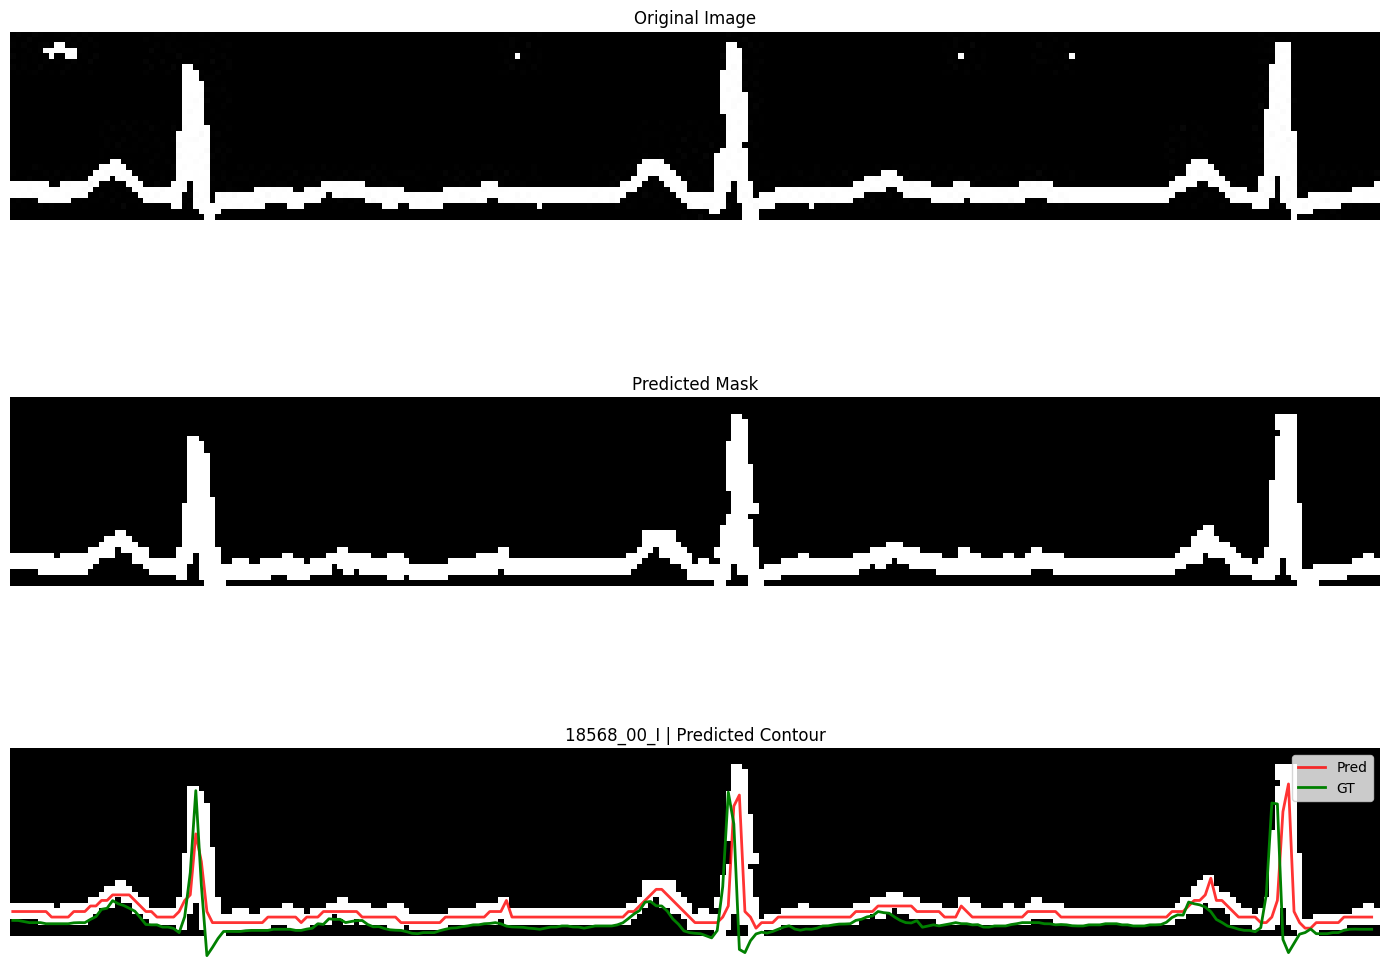

In [177]:
# filename_to_idx = {os.path.basename(f).replace(".jpg", ""): i for i, f in enumerate(files)}
# idx = filename_to_idx.get("21287_05_aVF")
from skimage.morphology import skeletonize

# Example: visualize a single file
test_mask = "" # Fill with your own path
visualize_file_matplotlib(test_mask)
